In [3]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 13.3 MB/s eta 0:00:00


######### 실습 데이터 생성 #################
X shape: (100, 2)
y shape: (100,)
First sample: [ 1.64565359 -0.5364869 ]
First label: 1

############ 데이터 시각화 #################


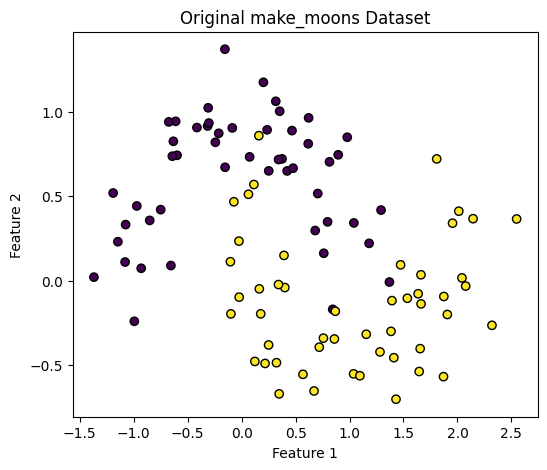


############ 데이터 스케일링 ###############
Before scaling -> min: [-1.3688344  -0.70039729] max: [2.54857762 1.36984215]
After scaling  -> min: [0. 0.] max: [3.14159265 3.14159265]

########## Train / Test 분리 ###############
X_train: (80, 2)
X_test: (20, 2)

########## Feature Dimension 결정 ################
Feature Dimension: 2

####### 기본 ZZFeatureMap 생성 ========
     ┌──────────────────────────┐
q_0: ┤0                         ├
     │  ZZFeatureMap(x[0],x[1]) │
q_1: ┤1                         ├
     └──────────────────────────┘

회로 시각화 (mpl):


/tmp/ipykernel_544/2220575747.py:71: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(


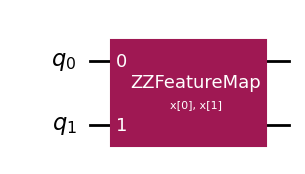


회로 시각화 (text):
     ┌──────────────────────────┐
q_0: ┤0                         ├
     │  ZZFeatureMap(x[0],x[1]) │
q_1: ┤1                         ├
     └──────────────────────────┘

Feature Map Parameters
----------------------
x[0]
x[1]

############ 실제 데이터 바인딩 ##########
Sample: [0.31880497 1.73476997]
     ┌──────────────────────────────┐
q_0: ┤0                             ├
     │  ZZFeatureMap(0.3188,1.7348) │
q_1: ┤1                             ├
     └──────────────────────────────┘
STEP 10. Bound Circuit


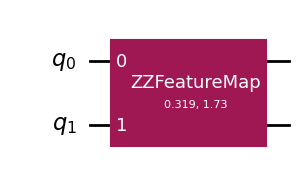

STEP 11. Compare reps
reps=1
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
reps=2
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
reps=3
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
STEP 12. Compare Entanglement
Entanglement: linear
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
Entanglement: full
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
Entanglement: circular
Depth : 1
Operations: OrderedDict({'ZZFeatureMap': 1})
--------------------------------------------------
STEP 13. Circuit Analysis
Number of Qubits     : 2
Number of Parameters : 2
Circuit Depth        : 1
Gate Count           : OrderedDict({'ZZFeatureMap': 1})

STEP 14. Quantum Kernel
Quantum Kernel Object Created Successfully:


/tmp/ipykernel_544/2220575747.py:118: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  fm = ZZFeatureMap(feature_dimension=2, reps=reps)
/tmp/ipykernel_544/2220575747.py:130: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  fm = ZZFeatureMap(feature_dimension=4, reps=1, entanglement=ent)


In [4]:
# 코랩 환경에서 Matplotlib 그래프 출력 활성화
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from qiskit.circuit.library import ZZFeatureMap  # 대문자 클래스 사용 권장

######### 실습 데이터 생성 #################
print("######### 실습 데이터 생성 #################")
X, y = make_moons(
    n_samples=100,
    noise=0.2,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First sample:", X[0])
print("First label:", y[0])
print()

############# 데이터 시각화 #################
print("############ 데이터 시각화 #################")
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", edgecolors="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original make_moons Dataset")
plt.show()

print()
############ 데이터 스케일링 ###############
print("############ 데이터 스케일링 ###############")

scaler = MinMaxScaler(feature_range=(0, np.pi))
X_scaled = scaler.fit_transform(X)

print("Before scaling -> min:", X.min(axis=0), "max:", X.max(axis=0))
print("After scaling  -> min:", X_scaled.min(axis=0), "max:", X_scaled.max(axis=0))
print()

########## Train / Test 분리 ###############
print("########## Train / Test 분리 ###############")

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print()

########## Feature Dimension 결정 ################
print("########## Feature Dimension 결정 ################")
feature_dimension = X_train.shape[1]
print("Feature Dimension:", feature_dimension)
print()

######## 기본 ZZFeatureMap 생성 ========
print("####### 기본 ZZFeatureMap 생성 ========")
# 최신 문법에 맞춰 대문자 ZZFeatureMap 사용
feature_map = ZZFeatureMap(
    feature_dimension=2,
    reps=1,
    entanglement="linear"
)
print(feature_map)

############### 회로 시각화 (코랩 display 활용) ###############
print("\n회로 시각화 (mpl):")
display(feature_map.draw("mpl"))

print("\n회로 시각화 (text):")
print(feature_map.draw("text"))
print()

########## 회로 파라미터 확인 ###########
print("Feature Map Parameters")
print("----------------------")
for param in feature_map.parameters:
    print(param)
print()

############ 실제 데이터 바인딩 ##########
print("############ 실제 데이터 바인딩 ##########")
sample = X_train[0]
print("Sample:", sample)

param_dict = {
    param: value
    for param, value in zip(feature_map.parameters, sample)
}

bound_circuit = feature_map.assign_parameters(param_dict)
print(bound_circuit.draw("text"))

########## Binding된 회로 출력 (코랩 display 활용) #############
print("=" * 60)
print("STEP 10. Bound Circuit")
print("=" * 60)
display(bound_circuit.draw("mpl"))

############## reps 비교 ##############
print("=" * 60)
print("STEP 11. Compare reps")
print("=" * 60)

for reps in [1, 2, 3]:
    fm = ZZFeatureMap(feature_dimension=2, reps=reps)
    print(f"reps={reps}")
    print("Depth :", fm.depth())
    print("Operations:", fm.count_ops())
    print("-" * 50)

############## Entanglement 비교 ##############
print("=" * 60)
print("STEP 12. Compare Entanglement")
print("=" * 60)

for ent in ["linear", "full", "circular"]:
    fm = ZZFeatureMap(feature_dimension=4, reps=1, entanglement=ent)
    print(f"Entanglement: {ent}")
    print("Depth :", fm.depth())
    print("Operations:", fm.count_ops())
    print("-" * 50)

############# 회로 복잡도 계산 ###############
print("=" * 60)
print("STEP 13. Circuit Analysis")
print("=" * 60)
print("Number of Qubits     :", feature_map.num_qubits)
print("Number of Parameters :", len(feature_map.parameters))
print("Circuit Depth        :", feature_map.depth())
print("Gate Count           :", feature_map.count_ops())
print()

################ Quantum Kernel 연결 ############
print("=" * 60)
print("STEP 14. Quantum Kernel")
print("=" * 60)

from qiskit_machine_learning.kernels import FidelityQuantumKernel

kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

print("Quantum Kernel Object Created Successfully:")
print(kernel)